In [ ]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import ast

# Set the default Seaborn theme
sns.set_theme(style="ticks")

# Load the dataset and parse dates
df = pd.read_csv("../data_jobs.csv", parse_dates=["job_posted_date"])

# Convert string representations of lists into actual Python lists
df["job_skills"] = df["job_skills"].apply(lambda x: ast.literal_eval(x) if pd.notna(x) else x)

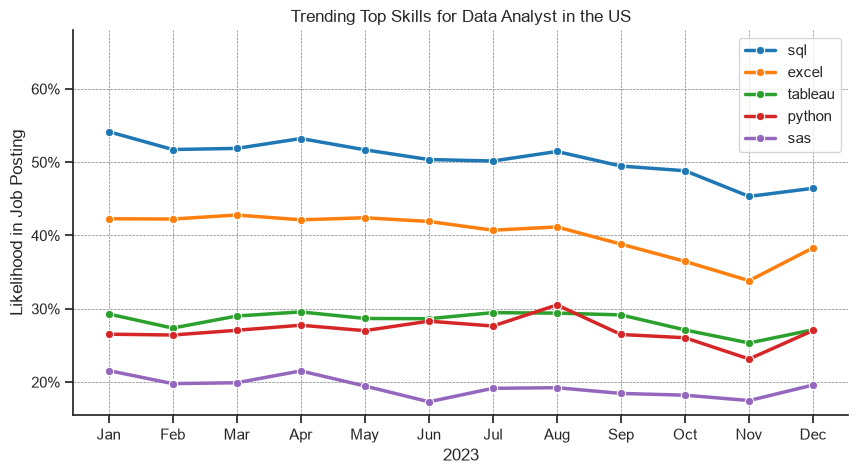

In [ ]:
# Filter Data Analyst job postings in the United States
df_DA_US = df[(df['job_title_short'] == 'Data Analyst') & (df['job_country'] == 'United States')]

# Extract the month number from the job posting date
df_DA_US['job_posted_month_no'] = df_DA_US['job_posted_date'].dt.month

# Expand the job_skills list so each skill occupies a separate row
df_DA_US_explode = df_DA_US.explode('job_skills')

# Get the five most frequently mentioned skills across all postings
top_skills = df_DA_US_explode['job_skills'].value_counts().index[:5]

# Create a pivot table counting each skill's mentions per month
df_DA_US_pivot = df_DA_US_explode.pivot_table(index='job_posted_month_no', columns='job_skills', aggfunc='size', fill_value=0)[top_skills]

# Count the total number of job postings for each month
postings_per_month = df_DA_US['job_posted_month_no'].value_counts()

# Calculate the percentage of monthly job postings mentioning each skill
df_DA_US_percent = df_DA_US_pivot.div(postings_per_month / 100, axis=0)

# Define month abbreviations for the x-axis
months = ["Jan", "Feb", "Mar", "Apr", "May", "Jun", "Jul", "Aug", "Sep", "Oct", "Nov", "Dec"]

# Replace month numbers with their corresponding abbreviations
df_DA_US_percent.index = months

# Create the figure and set its dimensions
plt.figure(figsize=(10, 5))

# Plot the monthly percentage trends for the top five skills
sns.lineplot(df_DA_US_percent, dashes=False, palette='tab10', marker='o',linewidth=2.5)

# Set the axis labels and chart title
plt.xlabel("2023")
plt.ylabel("Likelihood in Job Posting")
plt.title("Trending Top Skills for Data Analyst in the US")

# Set the upper limit of the y-axis
plt.ylim(top=68)

# Format y-axis tick labels as percentages
plt.gca().yaxis.set_major_formatter(plt.FuncFormatter(lambda y, _: f"{y:.0f}%"))  # type: ignore

# Add a dashed grid to improve readability
plt.grid(visible=True, color="gray", linewidth=0.5, linestyle="--")

# Remove the top and right borders for a cleaner appearance
sns.despine()

# Display the legend for the skill categories
plt.legend()

# Render the plot
plt.show()